# Prediction error can reveal word boundaries

An Elman recurrent network predicts the **next syllable** in a continuous stream of
Saffran, Aslin & Newport's (1996), Experiment 1A, artificial language.
It receives no spaces, word identities, boundary flags, or boundary-triggered resets.

| Word | Syllables |
|---|---|
| tupiro | tu · pi · ro |
| golabu | go · la · bu |
| bidaku | bi · da · ku |
| padoti | pa · do · ti |

The original familiarization used 45 copies of each word, without immediate word
repetitions: 180 words / 540 syllables over two minutes. This simulation uses the
same inventory and stream constraints, with **one training pass per model**:
540 observed syllables and 539 next-syllable targets. This matches the nominal
stimulus count, not the biological learning rate or infant behavioral response.

Run all cells in order. Colab usually includes the scientific dependencies;
locally, install `requirements.txt` and use your Python environment as the kernel.
This notebook is self-contained and needs no repository download in Colab.


## 1. Stimuli and recurrent network

One-hot vectors identify the 12 syllables. Input at time *t* predicts the syllable at *t + 1*. The recurrent state runs continuously across words.

In [1]:
"""Next-syllable prediction in Saffran et al. (1996), Experiment 1A.

Run ``python saffran_demo.py`` to train, evaluate, and regenerate the figure.
Word identities/boundaries are metadata and never enter the recurrent network.
"""
from __future__ import annotations

import argparse
import csv
import json
import math
from collections import Counter
from dataclasses import asdict, dataclass
from pathlib import Path
import sys

import numpy as np
import torch
from torch import nn
import torch.nn.functional as F

WORDS = {
    "tupiro": ("tu", "pi", "ro"),
    "golabu": ("go", "la", "bu"),
    "bidaku": ("bi", "da", "ku"),
    "padoti": ("pa", "do", "ti"),
}
WORD_NAMES = tuple(WORDS)
SYLLABLES = tuple(s for word in WORDS.values() for s in word)
TOKEN_ID = {s: i for i, s in enumerate(SYLLABLES)}


@dataclass(frozen=True)
class Config:
    seeds: tuple[int, ...] = (0, 1, 2, 3, 4)
    chunk_size: int = 16
    copies_per_word: int = 45
    hidden_size: int = 32
    learning_rate: float = 0.01
    test_seed: int = 2026

    def __post_init__(self):
        if not self.seeds or len(set(self.seeds)) != len(self.seeds):
            raise ValueError("Use at least one seed, with no duplicate seeds")
        if min(self.chunk_size, self.copies_per_word, self.hidden_size) < 1:
            raise ValueError("Training dimensions and counts must be positive")
        if any(not 0 <= seed < 2**32 for seed in self.seeds):
            raise ValueError("Model seeds must lie in [0, 2**32)")
        if self.learning_rate <= 0:
            raise ValueError("learning_rate must be positive")


@dataclass
class Stream:
    tokens: np.ndarray
    word_ids: np.ndarray
    is_boundary: np.ndarray

    @property
    def syllables(self):
        return [SYLLABLES[i] for i in self.tokens]


def make_stream(seed: int, copies_per_word: int = 45) -> Stream:
    """Balanced random word order, excluding immediate word repetitions.

    Choose from remaining word counts, weighted by availability. Restart if the
    final remaining words cannot be placed without an immediate repetition.
    This is a random balanced stream, not a claim of uniform sampling over all
    possible valid orders. Finite-stream transition frequencies are reported.
    """
    if copies_per_word < 1:
        raise ValueError("copies_per_word must be positive")
    rng = np.random.default_rng(seed)
    for _ in range(10000):
        remaining = np.full(len(WORDS), copies_per_word, dtype=int)
        order = []
        while remaining.sum():
            weights = remaining.copy()
            if order:
                weights[order[-1]] = 0
            if weights.sum() == 0:
                break
            choice = int(rng.choice(len(WORDS), p=weights / weights.sum()))
            order.append(choice)
            remaining[choice] -= 1
        if remaining.sum() == 0:
            ids = np.repeat(order, 3)
            tokens = np.array([TOKEN_ID[s] for i in order for s in WORDS[WORD_NAMES[i]]])
            boundaries = np.arange(len(tokens)) % 3 == 0
            boundaries[0] = False  # no preceding context at stream onset
            return Stream(tokens, ids, boundaries)
    raise RuntimeError("Could not generate a balanced nonrepeating stream")


def prediction_pairs(tokens: np.ndarray) -> tuple[torch.Tensor, torch.Tensor]:
    """Input at t predicts the target at t+1; batch axis comes first."""
    ids = torch.as_tensor(tokens, dtype=torch.long)
    if ids.ndim == 1:
        ids = ids.unsqueeze(0)
    return F.one_hot(ids[:, :-1], len(SYLLABLES)).float(), ids[:, 1:]


class ElmanNet(nn.Module):
    def __init__(self, hidden_size: int = 32):
        super().__init__()
        self.rnn = nn.RNN(len(SYLLABLES), hidden_size, batch_first=True)
        self.readout = nn.Linear(hidden_size, len(SYLLABLES))

    def forward(self, x, hidden=None):
        state, hidden = self.rnn(x, hidden)
        return self.readout(state), hidden




In [2]:
for word, syllables in WORDS.items():
    print(f'{word:7s}: {" · ".join(syllables)}')
preview = make_stream(2026)
print('\nModel input (first 24 syllables; no boundaries):')
print(' '.join(preview.syllables[:24]))

tupiro : tu · pi · ro
golabu : go · la · bu
bidaku : bi · da · ku
padoti : pa · do · ti

Model input (first 24 syllables; no boundaries):
tu pi ro bi da ku go la bu bi da ku go la bu pa do ti bi da ku tu pi ro


## 2. Learn during one brief exposure

The loss is cross-entropy, reported in bits. Each of five independent model seeds sees one 540-syllable stream, once. Online learning uses 16 prediction pairs per update (34 updates total). Hidden state values continue across chunks; gradients are detached between chunks. There are no word-boundary resets. Training and test word orders use separate seed ranges. No syllables are replayed for another epoch.

In [3]:
def train_model(config: Config, seed: int):
    """Learn online from one stream, never replaying any prediction target.

    Truncated backpropagation updates weights after each 16 prediction pairs.
    Hidden values continue across chunks; detaching only truncates the gradient.
    Chunk timing is independent of words: 16 is not a multiple of word length 3.
    """
    torch.manual_seed(seed)
    model = ElmanNet(config.hidden_size)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate)
    # The test seed range is [0, 2**32); this is a separate training word order.
    stream = make_stream(2**32 + seed, config.copies_per_word)
    x, targets = prediction_pairs(stream.tokens)
    history = []
    model.train()
    hidden = None
    for start in range(0, targets.shape[1], config.chunk_size):
        stop = start + config.chunk_size
        optimizer.zero_grad(set_to_none=True)
        logits, hidden = model(x[:, start:stop], hidden)
        loss = F.cross_entropy(logits.reshape(-1, len(SYLLABLES)), targets[:, start:stop].reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        hidden = hidden.detach()  # retain context; no reset at chunk/word boundaries
        history.append(float(loss.detach()) / math.log(2))
    return model, history


@torch.no_grad()
def evaluate(model: ElmanNet, stream: Stream) -> np.ndarray:
    """Surprisal in bits, aligned to each incoming target syllable.

    The initial syllable has no preceding input, so its error is undefined.
    The whole stream is evaluated continuously without word-boundary resets.
    """
    model.eval()
    x, targets = prediction_pairs(stream.tokens)
    logits, _ = model(x)
    error = F.cross_entropy(logits[0], targets[0], reduction="none") / math.log(2)
    return np.r_[np.nan, error.numpy()]


def bootstrap_mean_ci(values: np.ndarray, seed: int = 0):
    """Bootstrap independent model seeds, preserving paired time points."""
    values = np.asarray(values)
    if len(values) < 2:
        return values.mean(axis=0), None, None
    rng = np.random.default_rng(seed)
    samples = values[rng.integers(len(values), size=(10000, len(values)))].mean(axis=1)
    return values.mean(axis=0), *np.quantile(samples, [0.025, 0.975], axis=0)




## 3. Evaluate and plot model mean with uncertainty

The test word order is held out of training. Error is **−log₂ P(the incoming syllable | preceding syllables)**. A boundary-crossing error is plotted on the **first syllable of the new word**. The black line is the mean across five independently exposed models; the gray band is a pointwise 95% bootstrap confidence interval for that mean (10,000 resamples of model seeds). Each model sees only one training stream. There is no added noise or temporal smoothing. The test window is unchanged from the earlier figure. Word labels and dashed boundaries are added only for the reader.

In [4]:
# Bundled plotting assets: no network downloads or personal paths.
from pathlib import Path
Path('plotting/scripts/plot_style.py').parent.mkdir(parents=True, exist_ok=True)
Path('plotting/scripts/plot_style.py').write_text('"""Lu\'s small Matplotlib style/export helper; no statistical estimation."""\nfrom contextlib import contextmanager\nfrom pathlib import Path\n\nimport matplotlib as mpl\nimport matplotlib.pyplot as plt\nfrom matplotlib.backends.backend_agg import FigureCanvasAgg\nfrom matplotlib.figure import Figure\nimport seaborn as sns\n\nSTYLE_PATH = Path(__file__).resolve().parents[1] / \'lu.mplstyle\'\nDEFAULTS = mpl.rc_params_from_file(STYLE_PATH, use_default_template=False)\n\n\n@contextmanager\ndef plot_context(rc=None):\n    """Apply normal talk context and Lu\'s defaults locally; task overrides last."""\n    settings = dict(sns.plotting_context(\'talk\'))\n    settings.update(DEFAULTS)\n    settings[\'axes.prop_cycle\'] = mpl.cycler(color=sns.color_palette(\'colorblind\'))\n    if rc:\n        settings.update(rc)\n    with mpl.rc_context(settings):\n        yield\n\n\ndef new_panel(width=None, height=None, **kwargs):\n    """Create a single panel inside plot_context; dimensions are inches."""\n    default_width, default_height = mpl.rcParams[\'figure.figsize\']\n    return plt.subplots(figsize=(default_width if width is None else width,\n                                 default_height if height is None else height), **kwargs)\n\n\ndef _legend_entries(fig):\n    handles, labels = [], []\n    for ax in fig.axes:\n        legend = ax.get_legend()\n        if legend is not None:\n            hs = legend.legend_handles\n            ls = [text.get_text() for text in legend.get_texts()]\n        else:\n            hs, ls = ax.get_legend_handles_labels()\n        handles.extend(hs)\n        labels.extend(ls)\n    for legend in fig.legends:\n        handles.extend(legend.legend_handles)\n        labels.extend(text.get_text() for text in legend.get_texts())\n    # Shared labels must represent identical encodings. Supply explicit entries\n    # for intentionally repeated labels or custom legend handlers.\n    unique = {}\n    for handle, label in zip(handles, labels):\n        if label and not label.startswith(\'_\'):\n            unique.setdefault(label, handle)\n    return list(unique.values()), list(unique)\n\n\ndef _save_legend(handles, labels, path, dpi, ncol, legend_kwargs):\n    fig = Figure(figsize=(3.5, 3.5), dpi=dpi, facecolor=\'white\')\n    FigureCanvasAgg(fig)\n    legend = fig.legend(handles, labels, loc=\'center\', ncol=ncol, **legend_kwargs)\n    fig.canvas.draw()\n    bounds = legend.get_window_extent(fig.canvas.get_renderer())\n    fig.set_size_inches(bounds.width / dpi + .16, bounds.height / dpi + .16)\n    fig.canvas.draw()\n    path.parent.mkdir(parents=True, exist_ok=True)\n    with mpl.rc_context({\'savefig.bbox\': None}):\n        fig.savefig(path, dpi=dpi, format=path.suffix[1:], bbox_inches=None,\n                    facecolor=\'white\', transparent=False)\n\n\ndef save_panel(fig, path, *, caption, uncertainty, legend=True,\n               legend_path=None, legend_entries=None, legend_ncol=1,\n               legend_kwargs=None, dpi=None, output_format=None):\n    """Save a panel, separate legend if needed, and a standalone caption note.\n\n    Call inside plot_context after populating one panel. The helper cannot judge\n    whether a CI is meaningful or correct: uncertainty must explain the actual\n    interval or why none applies. Explicit output_format/dpi support user-requested\n    task overrides; a filename alone never silently enables another format.\n    """\n    if not isinstance(caption, str) or not caption.strip():\n        raise ValueError(\'A standalone caption is required.\')\n    if not isinstance(uncertainty, str) or not uncertainty.strip():\n        raise ValueError(\'An uncertainty definition or non-applicability explanation is required.\')\n    fmt = output_format or DEFAULTS[\'savefig.format\']\n    path = Path(path)\n    if path.suffix and path.suffix.lower() != \'.\' + fmt:\n        raise ValueError(\'Filename format differs from the requested format; pass output_format explicitly.\')\n    if not path.suffix:\n        path = path.with_suffix(\'.\' + fmt)\n    dpi = DEFAULTS[\'savefig.dpi\'] if dpi is None else dpi\n    entries = _legend_entries(fig) if legend_entries is None else legend_entries\n    handles, labels = list(entries[0]), list(entries[1])\n    if len(handles) != len(labels):\n        raise ValueError(\'Legend handles and labels must have equal lengths.\')\n    legend_output = None\n    if legend and handles:\n        # Even an explicitly requested vector panel keeps a PNG legend by default.\n        legend_output = Path(legend_path) if legend_path else path.with_name(path.stem + \'-legend.png\')\n        if legend_output.suffix.lower() != \'.png\' or legend_output.resolve() == path.resolve():\n            raise ValueError(\'The legend must have a distinct PNG path.\')\n    for ax in fig.axes:\n        if ax.get_legend() is not None:\n            ax.get_legend().remove()\n    for existing in list(fig.legends):\n        existing.remove()\n    fig.tight_layout()\n    path.parent.mkdir(parents=True, exist_ok=True)\n    # bbox_inches=None alone can inherit savefig.bbox=\'tight\'. Reset both.\n    with mpl.rc_context({\'savefig.bbox\': None}):\n        fig.savefig(path, format=fmt, dpi=dpi, bbox_inches=None,\n                    facecolor=\'white\', transparent=False)\n    if legend_output is not None:\n        _save_legend(handles, labels, legend_output, dpi, legend_ncol, legend_kwargs or {})\n    note = path.with_name(path.stem + \'.caption.md\')\n    content = caption.strip() + \'\\n\\nUncertainty: \' + uncertainty.strip() + \'\\n\'\n    if legend_output:\n        content += \'\\nLegend: \' + str(legend_output.name) + \'\\n\'\n    note.write_text(content, encoding=\'utf-8\')\n    return {\'panel\': path, \'legend\': legend_output, \'caption\': note}\n', encoding='utf-8')
Path('plotting/lu.mplstyle').parent.mkdir(parents=True, exist_ok=True)
Path('plotting/lu.mplstyle').write_text('# Layout/export defaults. Apply Seaborn talk context before this theme.\n# scripts/plot_style.py combines them automatically without global leakage.\nfigure.figsize: 3.5, 3.5\nfigure.autolayout: False\nfigure.constrained_layout.use: False\nfigure.facecolor: white\naxes.facecolor: white\naxes.spines.top: False\naxes.spines.right: False\naxes.grid: False\nlines.linestyle: -\naxes.prop_cycle: cycler(\'color\', [\'0173b2\', \'de8f05\', \'029e73\', \'d55e00\', \'cc78bc\', \'ca9161\', \'fbafe4\', \'949494\', \'ece133\', \'56b4e9\'])\nsavefig.facecolor: white\nsavefig.transparent: False\nsavefig.format: png\nsavefig.dpi: 300\nsavefig.bbox: standard\n# Typography and mark sizes come from sns.plotting_context("talk").\n# Choose categorical/continuous colors semantically; no exact palette is fixed.\n', encoding='utf-8')


760

In [5]:
def plot_prediction_error(errors, stream, output: Path, start_word=4, n_words=8,
                          model_seed=None, training_config: Config | None = None):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    import seaborn as sns
    sys.path.insert(0, str(Path.cwd() / "plotting" / "scripts"))
    from plot_style import plot_context, new_panel, save_panel

    start = start_word * 3
    stop = start + n_words * 3
    if start < 3 or n_words < 1 or stop > len(stream.tokens):
        raise ValueError("Plot window must follow warm-up and fit within the test stream")
    mean, low, high = bootstrap_mean_ci(errors[:, start:stop])
    x = np.arange(start, stop)
    with plot_context():
        fig, ax = new_panel(width=15.5)
        if low is not None:
            ax.fill_between(x, low, high, color="0.5", alpha=0.25, linewidth=0)
        ax.plot(x, mean, color="black")
        for first in range(start, stop, 3):
            ax.axvline(first - 0.5, color="0.72", linestyle="--", linewidth=1)
            word = WORD_NAMES[stream.word_ids[first]]
            ax.text(first + 1, 1.04, word, ha="center", va="bottom",
                    transform=ax.get_xaxis_transform())
        ax.set_xticks(x, stream.syllables[start:stop])
        ax.set_xlim(start - 0.5, stop - 0.5)
        ax.set_ylim(bottom=0)
        ax.set_ylabel("Prediction error (bits)")
        ax.set_xlabel("Incoming syllable →")
        sns.despine(ax=ax)
        uncertainty = ("Gray band: pointwise 95% bootstrap confidence interval for the mean over "
                       f"{len(errors)} independently trained model seeds (10,000 resamples). "
                       "This interval describes training variability, not infant variability."
                       if len(errors) > 1 else
                       "No interval: raw predictions from one trained model on a fixed held-out word order; "
                       "the line is not a model average. No synthetic noise or smoothing is applied.")
        seed_label = f"model seed {model_seed}" if model_seed is not None else "one model"
        series = (f"raw surprisal from {seed_label}" if len(errors) == 1
                  else f"mean surprisal across {len(errors)} model seeds")
        training_config = training_config or Config()
        training_syllables = training_config.copies_per_word * 12
        training_targets = training_syllables - 1
        updates = math.ceil(training_targets / training_config.chunk_size)
        caption = (f"Next-syllable prediction in an Elman recurrent network trained on the four "
                   f"Saffran et al. (1996), Experiment 1A, words. Black line: {series}, "
                   "−log₂ P(observed syllable | preceding syllables) on a held-out stream. "
                   "Dashed lines are word boundaries; word labels and boundaries are display metadata, "
                   f"never model inputs. {n_words} consecutive words are shown after {start_word} warm-up words. "
                   f"One training pass uses {training_syllables} observed syllables ({training_targets} next-syllable targets), "
                   f"with {updates} updates and chunk size {training_config.chunk_size}. "
                   f"At 270 syllables/minute this is nominally {training_syllables / 270:g} minutes of stimulus, "
                   "not a claim of matching biological learning rates. "
                   "Error is plotted at the incoming target syllable, so boundary-crossing errors "
                   f"appear on the first syllable of the next word. All {int(stream.is_boundary.sum())} boundary transitions and "
                   f"{int((~stream.is_boundary).sum()) - 1} within-word transitions in the {len(stream.tokens)}-syllable test stream enter the summary. "
                   "The first syllable is excluded because it has no preceding context.")
        save_panel(fig, output, caption=caption, uncertainty=uncertainty)
        plt.close(fig)


def transition_report(stream):
    counts = Counter(zip(stream.tokens[:-1].tolist(), stream.tokens[1:].tolist()))
    totals = Counter(stream.tokens[:-1].tolist())
    return [{"from": SYLLABLES[a], "to": SYLLABLES[b], "count": n,
             "probability": n / totals[a]}
            for (a, b), n in sorted(counts.items())]


def run(config: Config, output_dir: Path):
    if not 0 <= config.test_seed < 2**32:
        raise ValueError("test_seed must lie in [0, 2**32) for separation from training seeds")
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)
    output_dir.mkdir(parents=True, exist_ok=True)
    test = make_stream(config.test_seed, config.copies_per_word)
    errors, histories = [], []
    for seed in config.seeds:
        model, history = train_model(config, seed)
        errors.append(evaluate(model, test))
        histories.append(history)
        print(f"Seed {seed}: final training loss = {history[-1]:.3f} bits", flush=True)
    errors = np.stack(errors)
    eligible = np.arange(len(test.tokens)) > 0
    masks = {"boundary": test.is_boundary, "within_word": eligible & ~test.is_boundary}
    summary = {}
    for name, mask in masks.items():
        values = errors[:, mask].mean(axis=1)
        mean, low, high = bootstrap_mean_ci(values)
        summary[name] = {"mean_bits": float(mean), "per_seed_bits": values.tolist(),
                         "ci95_bits": None if low is None else [float(low), float(high)],
                         "transitions_per_seed": int(mask.sum())}
    metadata = {
        "config": asdict(config), "words": WORDS, "summary": summary,
        "metric": "-log2 P(incoming target syllable | preceding syllables)",
        "training_passes": 1,
        "training_streams_per_seed": 1,
        "training_stream_seeds": {str(seed): 2**32 + seed for seed in config.seeds},
        "training_syllables_per_seed": config.copies_per_word * 12,
        "training_targets_per_seed": config.copies_per_word * 12 - 1,
        "optimizer_updates_per_seed": len(histories[0]),
        "nominal_training_stimulus_minutes_at_270_syllables_per_minute": config.copies_per_word * 12 / 270,
        "plotted_seeds": list(config.seeds),
        "plotted_series": ("mean across model seeds with pointwise 95% bootstrap CI; fixed test window"
                           if len(config.seeds) > 1 else "raw single-model predictions; fixed test window"),
        "test_syllables": len(test.tokens),
        "test_word_sequence": [WORD_NAMES[i] for i in test.word_ids[::3]],
        "test_empirical_transitions": transition_report(test),
        "versions": {"python": sys.version.split()[0], "torch": torch.__version__, "numpy": np.__version__},
        "interpretation": "One-pass computational adaptation matching the original nominal syllable count; not a claim of equivalent infant/model learning rates or a replication of infant behavioral responses.",
    }
    (output_dir / "summary.json").write_text(json.dumps(metadata, indent=2) + "\n")
    with (output_dir / "prediction_errors.csv").open("w", newline="") as file:
        writer = csv.writer(file, lineterminator="\n")
        writer.writerow(["seed", "time", "syllable", "word", "boundary_crossing", "error_bits"])
        for seed, row in zip(config.seeds, errors):
            for t in range(1, len(row)):
                writer.writerow([seed, t, SYLLABLES[test.tokens[t]], WORD_NAMES[test.word_ids[t]],
                                 int(test.is_boundary[t]), float(row[t])])
    with (output_dir / "training_loss.csv").open("w", newline="") as file:
        writer = csv.writer(file, lineterminator="\n")
        writer.writerow(["seed", "step", "cumulative_prediction_targets", "loss_bits"])
        writer.writerows((seed, step + 1, min((step + 1) * config.chunk_size, len(test.tokens) - 1), value)
                         for seed, h in zip(config.seeds, histories)
                         for step, value in enumerate(h))
    plot_prediction_error(errors, test, output_dir.parent / "imgs" / "saffran-one-pass-prediction-error.png",
                          model_seed=config.seeds[0], training_config=config)
    print(json.dumps(summary, indent=2), flush=True)
    return errors, test, metadata



In [6]:
errors, test_stream, result = run(Config(), Path('results'))

Seed 0: final training loss = 1.050 bits


Seed 1: final training loss = 1.301 bits


Seed 2: final training loss = 1.440 bits


Seed 3: final training loss = 0.938 bits


Seed 4: final training loss = 1.455 bits


{
  "boundary": {
    "mean_bits": 2.0065090656280518,
    "per_seed_bits": [
      1.9906038045883179,
      2.0523247718811035,
      2.06986403465271,
      1.9642388820648193,
      1.9555128812789917
    ],
    "ci95_bits": [
      1.9660215377807617,
      2.0469963550567627
    ],
    "transitions_per_seed": 179
  },
  "within_word": {
    "mean_bits": 0.7189310193061829,
    "per_seed_bits": [
      0.5825459957122803,
      0.7944643497467041,
      0.824806272983551,
      0.5489645004272461,
      0.8438740372657776
    ],
    "ci95_bits": [
      0.6114970445632935,
      0.8263649940490723
    ],
    "transitions_per_seed": 360
  }
}


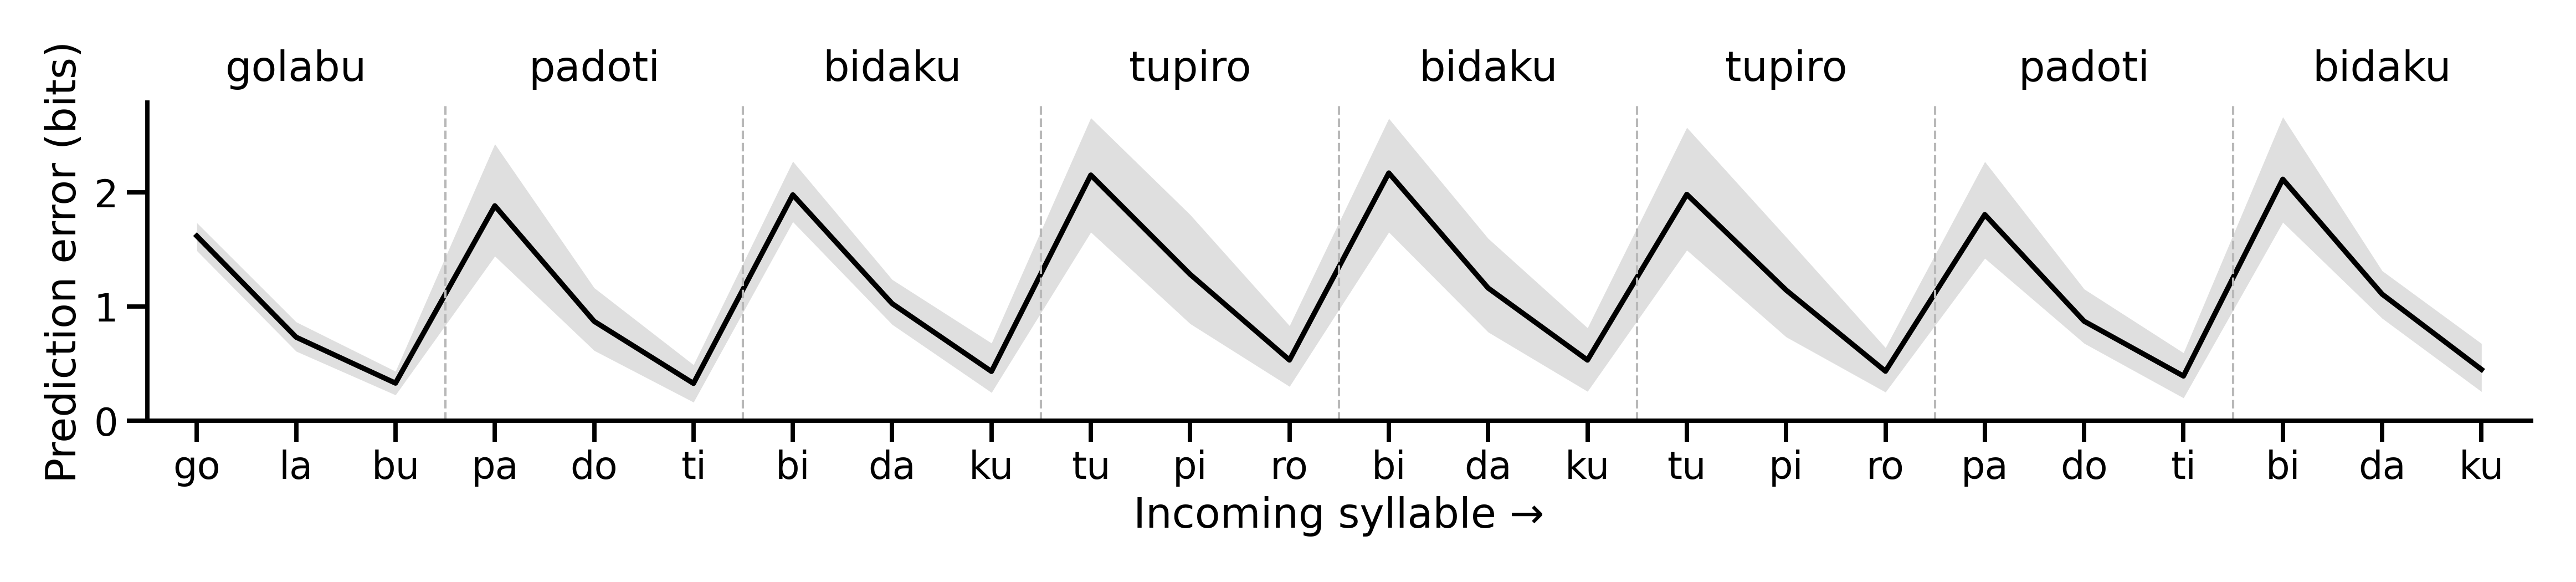

Next-syllable prediction in an Elman recurrent network trained on the four Saffran et al. (1996), Experiment 1A, words. Black line: mean surprisal across 5 model seeds, −log₂ P(observed syllable | preceding syllables) on a held-out stream. Dashed lines are word boundaries; word labels and boundaries are display metadata, never model inputs. 8 consecutive words are shown after 4 warm-up words. One training pass uses 540 observed syllables (539 next-syllable targets), with 34 updates and chunk size 16. At 270 syllables/minute this is nominally 2 minutes of stimulus, not a claim of matching biological learning rates. Error is plotted at the incoming target syllable, so boundary-crossing errors appear on the first syllable of the next word. All 179 boundary transitions and 360 within-word transitions in the 540-syllable test stream enter the summary. The first syllable is excluded because it has no preceding context.

Uncertainty: Gray band: pointwise 95% bootstrap confidence interval for 

In [7]:
from IPython.display import Image, display
display(Image(filename='imgs/saffran-one-pass-prediction-error.png'))
print(Path('imgs/saffran-one-pass-prediction-error.caption.md').read_text())

## Interpretation

Within each word, the next syllable is fixed. Across word boundaries, the next word
can be any of the other three: nominal transition probability 1/3. A well-trained
predictor should therefore approach 0 bits within words and log₂(3) ≈ 1.585 bits
across boundaries. This briefly exposed model remains imperfect, so both within-word
and boundary errors vary. Finite sampled streams and model estimation cause deviations.

The model is trained only on prediction, not explicit segmentation labels.
Higher boundary error is evidence of a useful segmentation cue, not proof that a
separate explicit word-segmentation representation has been learned.

The full test stream, per-seed errors, training losses, empirical transition
probabilities, and configuration are saved under `results/`.

References: [Elman (1990), Finding Structure in Time](https://doi.org/10.1016/0364-0213(90)90002-E);
[Saffran, Aslin & Newport (1996), Statistical Learning by 8-Month-Old Infants](https://doi.org/10.1126/science.274.5294.1926).
